LOADING DATASET KEEPING ONLY ESSENTIAL COLUMNS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define the essential columns for our initial analysis
cols_to_keep = [
    'loan_amnt', 'term', 'int_rate', 'grade', 'sub_grade', 'emp_length',
    'home_ownership', 'annual_inc', 'verification_status', 'issue_d',
    'loan_status', 'purpose', 'dti', 'fico_range_low', 'fico_range_high',
    'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal',
    'revol_util', 'total_acc'
]

file_path = r"C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\data\raw\lending_club\accepted_2007_to_2018Q4.csv"

print("Loading a safe sample of the data (500,000 rows)...")
# We use nrows to load only the first 500k rows for now
df = pd.read_csv(file_path, usecols=cols_to_keep, nrows=500_000, low_memory=False)

print(f"Sample dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")

# Define the target variable
valid_statuses = ['Fully Paid', 'Charged Off']
df = df[df['loan_status'].isin(valid_statuses)].copy()
df['target'] = np.where(df['loan_status'] == 'Charged Off', 1, 0)

print(f"\nDataset after filtering for final statuses: {df.shape[0]:,} rows")
print(f"Bad Rate (Charged Off): {df['target'].mean():.2%}")

df.drop(columns=['loan_status'], inplace=True)

Loading a safe sample of the data (500,000 rows)...
Sample dataset loaded: 500,000 rows, 22 columns

Dataset after filtering for final statuses: 391,164 rows
Bad Rate (Charged Off): 20.15%


The Stratified Sample (Memory-Safe)

In [2]:
from sklearn.model_selection import train_test_split

# Let's pull the 'issue_d' back in temporarily just for the stratified split
file_path = r"C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\data\raw\lending_club\accepted_2007_to_2018Q4.csv"
cols_to_keep = ['loan_amnt', 'term', 'int_rate', 'grade', 'sub_grade', 'emp_length', 
                'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 
                'loan_status', 'purpose', 'dti', 'fico_range_low', 'fico_range_high',
                'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 
                'revol_util', 'total_acc']

# Load the first 500k rows again
df_raw = pd.read_csv(file_path, usecols=cols_to_keep, nrows=500_000, low_memory=False)

# Filter to final statuses
df_raw = df_raw[df_raw['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
df_raw['target'] = np.where(df_raw['loan_status'] == 'Charged Off', 1, 0)

# STRATIFIED SAMPLE: We stratify by Year and Target to ensure the sample 
# represents every year, not just 2018.
df_raw['issue_year'] = pd.to_datetime(df_raw['issue_d'], format='%b-%Y').dt.year
df_raw['strat_key'] = df_raw['issue_year'].astype(str) + "_" + df_raw['target'].astype(str)

# Drop any rows where we couldn't parse the date
df_raw = df_raw.dropna(subset=['issue_year'])

# Create the sample
sample_df, _ = train_test_split(
    df_raw, 
    train_size=150_000, 
    stratify=df_raw['strat_key'], 
    random_state=42
)

print(f"Stratified Sample Shape: {sample_df.shape}")
print(f"Sample Bad Rate: {sample_df['target'].mean():.2%}")

Stratified Sample Shape: (150000, 25)
Sample Bad Rate: 20.15%


The Data Audit Prompt

In [3]:
import io
import sys

buffer = io.StringIO()
sample_df.info(buf=buffer)
info_str = buffer.getvalue()

print("--- COLUMN INFO ---")
print(info_str)

print("\n--- MISSING VALUES ---")
print(sample_df.isnull().sum()[sample_df.isnull().sum() > 0])
print("\n--- CATEGORICAL UNIQUE VALUES ---")
for col in sample_df.select_dtypes(include=['object']).columns:
    print(f"{col}: {sample_df[col].nunique()} unique values. Examples: {sample_df[col].dropna().unique()[:5]}")

--- COLUMN INFO ---
<class 'pandas.DataFrame'>
Index: 150000 entries, 190611 to 382250
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   loan_amnt            150000 non-null  float64
 1   term                 150000 non-null  str    
 2   int_rate             150000 non-null  float64
 3   grade                150000 non-null  str    
 4   sub_grade            150000 non-null  str    
 5   emp_length           140958 non-null  str    
 6   home_ownership       150000 non-null  str    
 7   annual_inc           150000 non-null  float64
 8   verification_status  150000 non-null  str    
 9   issue_d              150000 non-null  str    
 10  loan_status          150000 non-null  str    
 11  purpose              150000 non-null  str    
 12  dti                  149981 non-null  float64
 13  delinq_2yrs          150000 non-null  float64
 14  fico_range_low       150000 non-null  float64
 15  fico_ran

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21376\3280789579.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in sample_df.select_dtypes(include=['object']).columns:


purpose: 13 unique values. Examples: <ArrowStringArray>
['debt_consolidation', 'credit_card', 'major_purchase', 'car', 'medical']
Length: 5, dtype: str
strat_key: 4 unique values. Examples: <ArrowStringArray>
['2015_0', '2015_1', '2018_0', '2018_1']
Length: 4, dtype: str


TOTAL NUMBER OF LOANS AND BAD RATES PER VINTAGE

In [4]:
import pandas as pd
import numpy as np

file_path = r"C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\data\raw\lending_club\accepted_2007_to_2018Q4.csv"

print("Extracting just the dates and statuses for the entire 2.2M dataset...")
# We only load 2 columns. This is super fast and memory safe.
df_time = pd.read_csv(file_path, usecols=['issue_d', 'loan_status'], low_memory=False)

# Filter to final statuses
df_time = df_time[df_time['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
df_time['target'] = np.where(df_time['loan_status'] == 'Charged Off', 1, 0)

# Convert issue_d to a year
df_time['issue_year'] = pd.to_datetime(df_time['issue_d'], format='%b-%Y').dt.year

# Group by year to see the true distribution
yearly_summary = df_time.groupby('issue_year').agg(
    Total_Loans=('target', 'count'),
    Bad_Rate=('target', 'mean')
).reset_index()

print(yearly_summary.to_string())

Extracting just the dates and statuses for the entire 2.2M dataset...
    issue_year  Total_Loans  Bad_Rate
0         2007          251  0.179283
1         2008         1562  0.158131
2         2009         4716  0.125954
3         2010        11536  0.128901
4         2011        21721  0.151789
5         2012        53367  0.161973
6         2013       134804  0.155960
7         2014       223102  0.184494
8         2015       375545  0.201848
9         2016       293095  0.232832
10        2017       169300  0.231234
11        2018        56311  0.157465


The Correct Stratified Sample
Run this code. It loads the full 2.2M dataset, but using only 22 columns to prevent the VSCODE crash, and then mathematically guarantees the sample is a perfect replica of the true timeline.

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

file_path = r"C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\data\raw\lending_club\accepted_2007_to_2018Q4.csv"

# 1. Define the 22 columns we need (dropping the 130+ useless/leakage ones)
cols_to_keep = [
    'loan_amnt', 'term', 'int_rate', 'grade', 'sub_grade', 'emp_length', 
    'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 
    'loan_status', 'purpose', 'dti', 'fico_range_low', 'fico_range_high',
    'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 
    'revol_util', 'total_acc'
]

print("Loading full 2.2M dataset (only 22 columns)...")
df_full = pd.read_csv(file_path, usecols=cols_to_keep, low_memory=False)

# 2. Filter to terminal statuses only
df_full = df_full[df_full['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
df_full['target'] = np.where(df_full['loan_status'] == 'Charged Off', 1, 0)

# 3. Extract the Year for stratification
df_full['issue_year'] = pd.to_datetime(df_full['issue_d'], format='%b-%Y').dt.year

# 4. Create a combined stratify key (Year + Target)
# This ensures the model sees the exact bad rate for each year
df_full['strat_key'] = df_full['issue_year'].astype(str) + "_" + df_full['target'].astype(str)

print(f"Total population: {len(df_full):,} loans")

# 5. Take a perfectly stratified sample of 150,000 loans
sample_df, _ = train_test_split(
    df_full, 
    train_size=150_000, 
    stratify=df_full['strat_key'], 
    random_state=42
)

# 6. Verify the sample matches the population
print("\n--- VERIFICATION: Population vs Sample ---")
pop_check = df_full.groupby('issue_year').agg(Pop_Count=('target', 'count'), Pop_Bad_Rate=('target', 'mean'))
sample_check = sample_df.groupby('issue_year').agg(Sample_Count=('target', 'count'), Sample_Bad_Rate=('target', 'mean'))
verify = pop_check.join(sample_check)
verify['Sample_Count'] = verify['Sample_Count'].astype(int)

print(verify[['Pop_Count', 'Sample_Count', 'Pop_Bad_Rate', 'Sample_Bad_Rate']].round(4).to_string())

# Cleanup memory
del df_full

Loading full 2.2M dataset (only 22 columns)...
Total population: 1,345,310 loans

--- VERIFICATION: Population vs Sample ---
            Pop_Count  Sample_Count  Pop_Bad_Rate  Sample_Bad_Rate
issue_year                                                        
2007              251            28        0.1793           0.1786
2008             1562           174        0.1581           0.1552
2009             4716           526        0.1260           0.1255
2010            11536          1286        0.1289           0.1291
2011            21721          2422        0.1518           0.1519
2012            53367          5950        0.1620           0.1620
2013           134804         15030        0.1560           0.1560
2014           223102         24875        0.1845           0.1845
2015           375545         41873        0.2018           0.2018
2016           293095         32680        0.2328           0.2328
2017           169300         18877        0.2312           0.2312
2018

Testing for Potential Data Quality Issues on the Selected Columns

In [6]:
import io
buffer = io.StringIO()
sample_df.info(buf=buffer)
print(buffer.getvalue())

print("\n--- MISSING VALUES ---")
print(sample_df.isnull().sum()[sample_df.isnull().sum() > 0])

<class 'pandas.DataFrame'>
Index: 150000 entries, 542817 to 1030736
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   loan_amnt            150000 non-null  float64
 1   term                 150000 non-null  str    
 2   int_rate             150000 non-null  float64
 3   grade                150000 non-null  str    
 4   sub_grade            150000 non-null  str    
 5   emp_length           141208 non-null  str    
 6   home_ownership       150000 non-null  str    
 7   annual_inc           150000 non-null  float64
 8   verification_status  150000 non-null  str    
 9   issue_d              150000 non-null  str    
 10  loan_status          150000 non-null  str    
 11  purpose              150000 non-null  str    
 12  dti                  149954 non-null  float64
 13  delinq_2yrs          150000 non-null  float64
 14  fico_range_low       150000 non-null  float64
 15  fico_range_high      150000

THe Data Cleaning Code

In [10]:
import pandas as pd
import numpy as np

# --- 1. INITIALIZE AUDIT LOG ---
audit_log = []
initial_rows = len(sample_df)
audit_log.append({"Step": "Initial Loaded Sample", "Action": "None", "Rows_Affected": initial_rows, "Reason": "Baseline"})

# --- 2. CLEAN STRING COLUMNS (BULLETPROOF) ---

# FIX: Cast to string first, so it works even if you run it twice
sample_df['term'] = sample_df['term'].astype(str).str.extract('(\d+)').fillna(0).astype(int)
sample_df['int_rate'] = sample_df['int_rate'].astype(str).str.replace('%', '').astype(float)
sample_df['revol_util'] = sample_df['revol_util'].astype(str).str.replace('%', '').astype(float)

# FIX: Check if the value is already an integer/float before cleaning
def clean_emp_length(val):
    if pd.isna(val): return np.nan
    if isinstance(val, (int, float)): return val # If already cleaned, skip!
    if '< 1' in val: return 0
    elif '10+' in val: return 10
    else: 
        try:
            return int(val.split(' ')[0])
        except:
            return np.nan

sample_df['emp_length'] = sample_df['emp_length'].apply(clean_emp_length)

audit_log.append({"Step": "String Parsing", "Action": "Transformed", "Rows_Affected": len(sample_df), "Reason": "Converted '36 months' to 36, '13.5%' to 13.5, and '10+ years' to 10."})

# --- 3. HANDLE MISSING VALUES (WITH AUDIT) ---
rows_before_drop = len(sample_df)
sample_df.dropna(subset=['dti', 'revol_util', 'inq_last_6mths'], inplace=True)
rows_dropped = rows_before_drop - len(sample_df)
audit_log.append({"Step": "Missing DTI/Util/Inquiries", "Action": "Dropped", "Rows_Affected": rows_dropped, "Reason": f"Missing critical credit data."})

rows_to_impute = sample_df['emp_length'].isnull().sum()
median_emp = sample_df['emp_length'].median()
sample_df['emp_length'] = sample_df['emp_length'].fillna(median_emp)
audit_log.append({"Step": "Missing Emp Length", "Action": "Imputed", "Rows_Affected": rows_to_impute, "Reason": f"Imputed with median ({median_emp} years) to avoid losing data."})

# --- 4. DROP UNUSED COLUMNS ---
cols_to_drop = ['issue_d', 'issue_year', 'strat_key', 'loan_status']
sample_df.drop(columns=cols_to_drop, inplace=True, errors='ignore')
audit_log.append({"Step": "Drop Columns", "Action": "Dropped Columns", "Rows_Affected": 0, "Reason": "Target leakage and time-based columns removed."})

# --- 5. PRINT & SAVE AUDIT LOG ---
audit_df = pd.DataFrame(audit_log)
print("=========================================")
print("      DATA CLEANING AUDIT TRAIL          ")
print("=========================================")
print(audit_df.to_string(index=False))
print("=========================================")
print(f"Final Row Count: {len(sample_df)}")
print(f"Total Rows Dropped: {rows_dropped} ({(rows_dropped/initial_rows)*100:.4f}%)")

output_path = r"C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\data_cleaning_audit_log.csv"
audit_df.to_csv(output_path, index=False)
print(f"Audit log saved successfully to: {output_path}")

<>:12: SyntaxWarning: invalid escape sequence '\d'
<>:12: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21376\333826513.py:12: SyntaxWarning: invalid escape sequence '\d'
  sample_df['term'] = sample_df['term'].astype(str).str.extract('(\d+)').fillna(0).astype(int)


      DATA CLEANING AUDIT TRAIL          
                      Step          Action  Rows_Affected                                                               Reason
     Initial Loaded Sample            None         149850                                                             Baseline
            String Parsing     Transformed         149850 Converted '36 months' to 36, '13.5%' to 13.5, and '10+ years' to 10.
Missing DTI/Util/Inquiries         Dropped              0                                        Missing critical credit data.
        Missing Emp Length         Imputed              0                Imputed with median (6.0 years) to avoid losing data.
              Drop Columns Dropped Columns              0                       Target leakage and time-based columns removed.
Final Row Count: 149850
Total Rows Dropped: 0 (0.0000%)
Audit log saved successfully to: C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\data_cleaning_audit_log.csv


EXPLORATORY DATA ANALYSIS (EDA)

Block 1: Univariate Distributions (Histograms & KDE)
Why we do this: We want to see the shape of the data. Is income skewed? Are loan amounts normally distributed? Do we have outliers that will break a Logistic Regression?

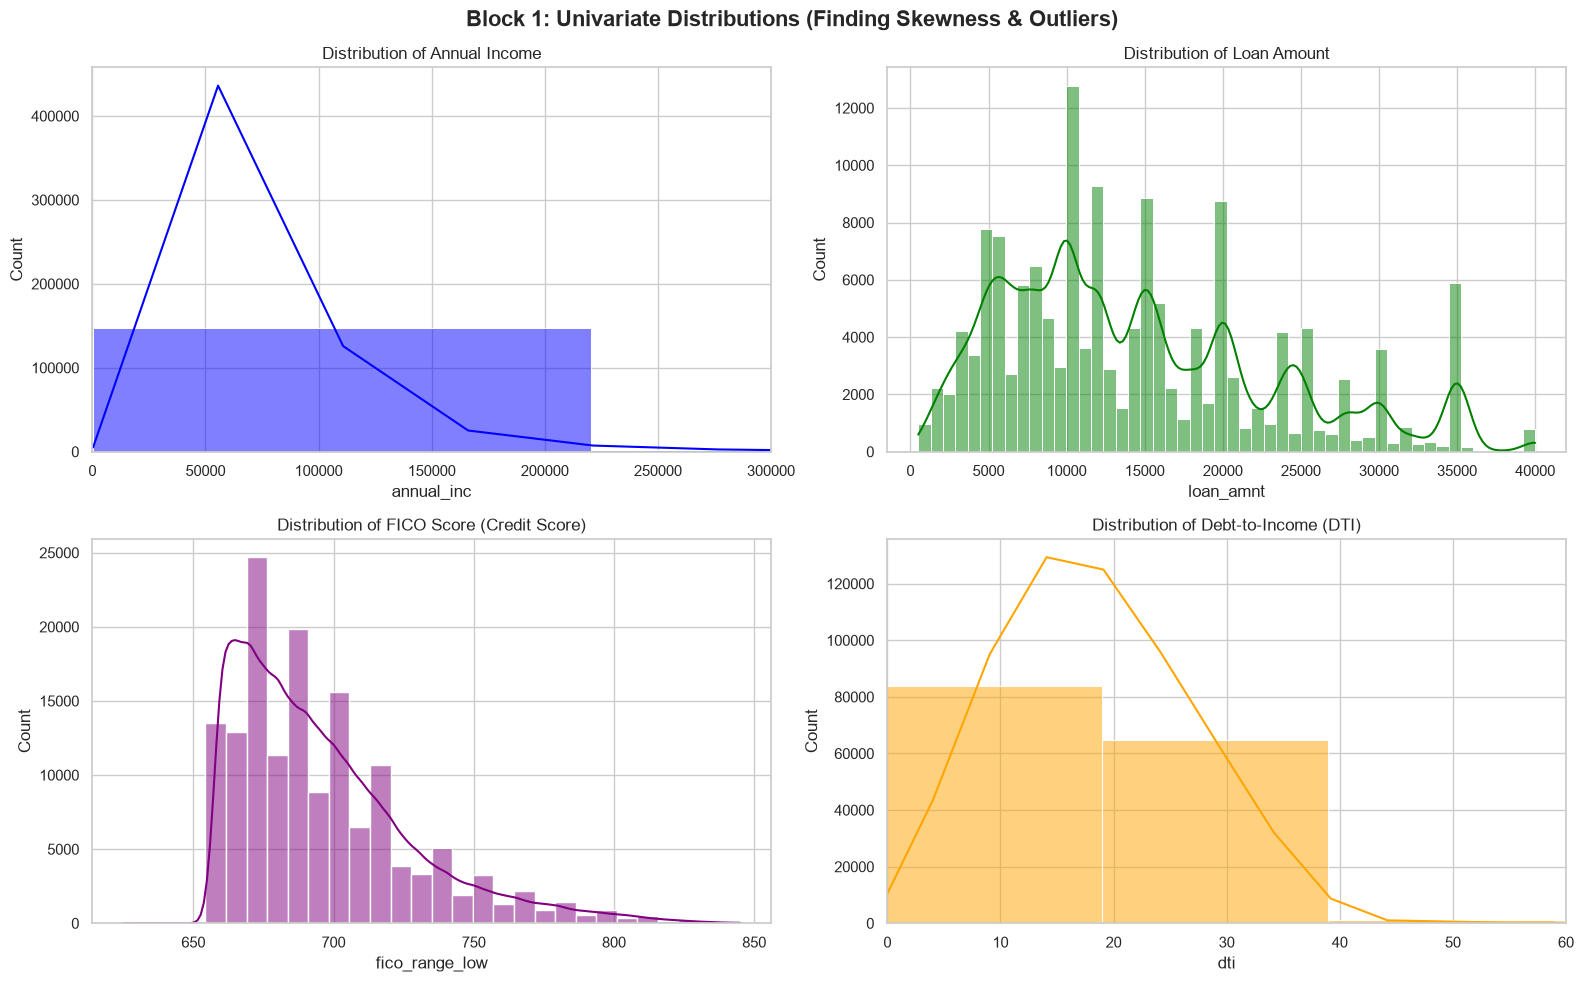

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Block 1: Univariate Distributions (Finding Skewness & Outliers)', fontsize=16, fontweight='bold')

# 1. Annual Income (We expect massive right-skew)
sns.histplot(sample_df['annual_inc'], bins=50, kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Distribution of Annual Income')
axes[0, 0].set_xlim(0, 300000) # Capping X-axis to see the bulk of the data

# 2. Loan Amount (Likely a mix of 36-month and 60-month peaks)
sns.histplot(sample_df['loan_amnt'], bins=50, kde=True, ax=axes[0, 1], color='green')
axes[0, 1].set_title('Distribution of Loan Amount')

# 3. FICO Score (Should look like a bell curve)
sns.histplot(sample_df['fico_range_low'], bins=30, kde=True, ax=axes[1, 0], color='purple')
axes[1, 0].set_title('Distribution of FICO Score (Credit Score)')

# 4. DTI (Debt-to-Income)
sns.histplot(sample_df['dti'], bins=50, kde=True, ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Distribution of Debt-to-Income (DTI)')
axes[1, 1].set_xlim(0, 60) # Capping X-axis

plt.tight_layout()
plt.show()

Block 2: Categorical Default Rates (Bar Charts)
Why we do this: To see how default rates differ across segments. Does a 60-month loan default more than a 36-month loan? Are "Debt Consolidation" loans riskier than "Credit Card" loans?

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21376\4169318716.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=term_risk, x='term', y='target', ax=axes[0, 0], palette='Blues_d')
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21376\4169318716.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=grade_risk, x='grade', y='target', ax=axes[0, 1], palette='Reds_d', order=['A','B','C','D','E','F','G'])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21376\4169318716.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=home_risk, x='ho

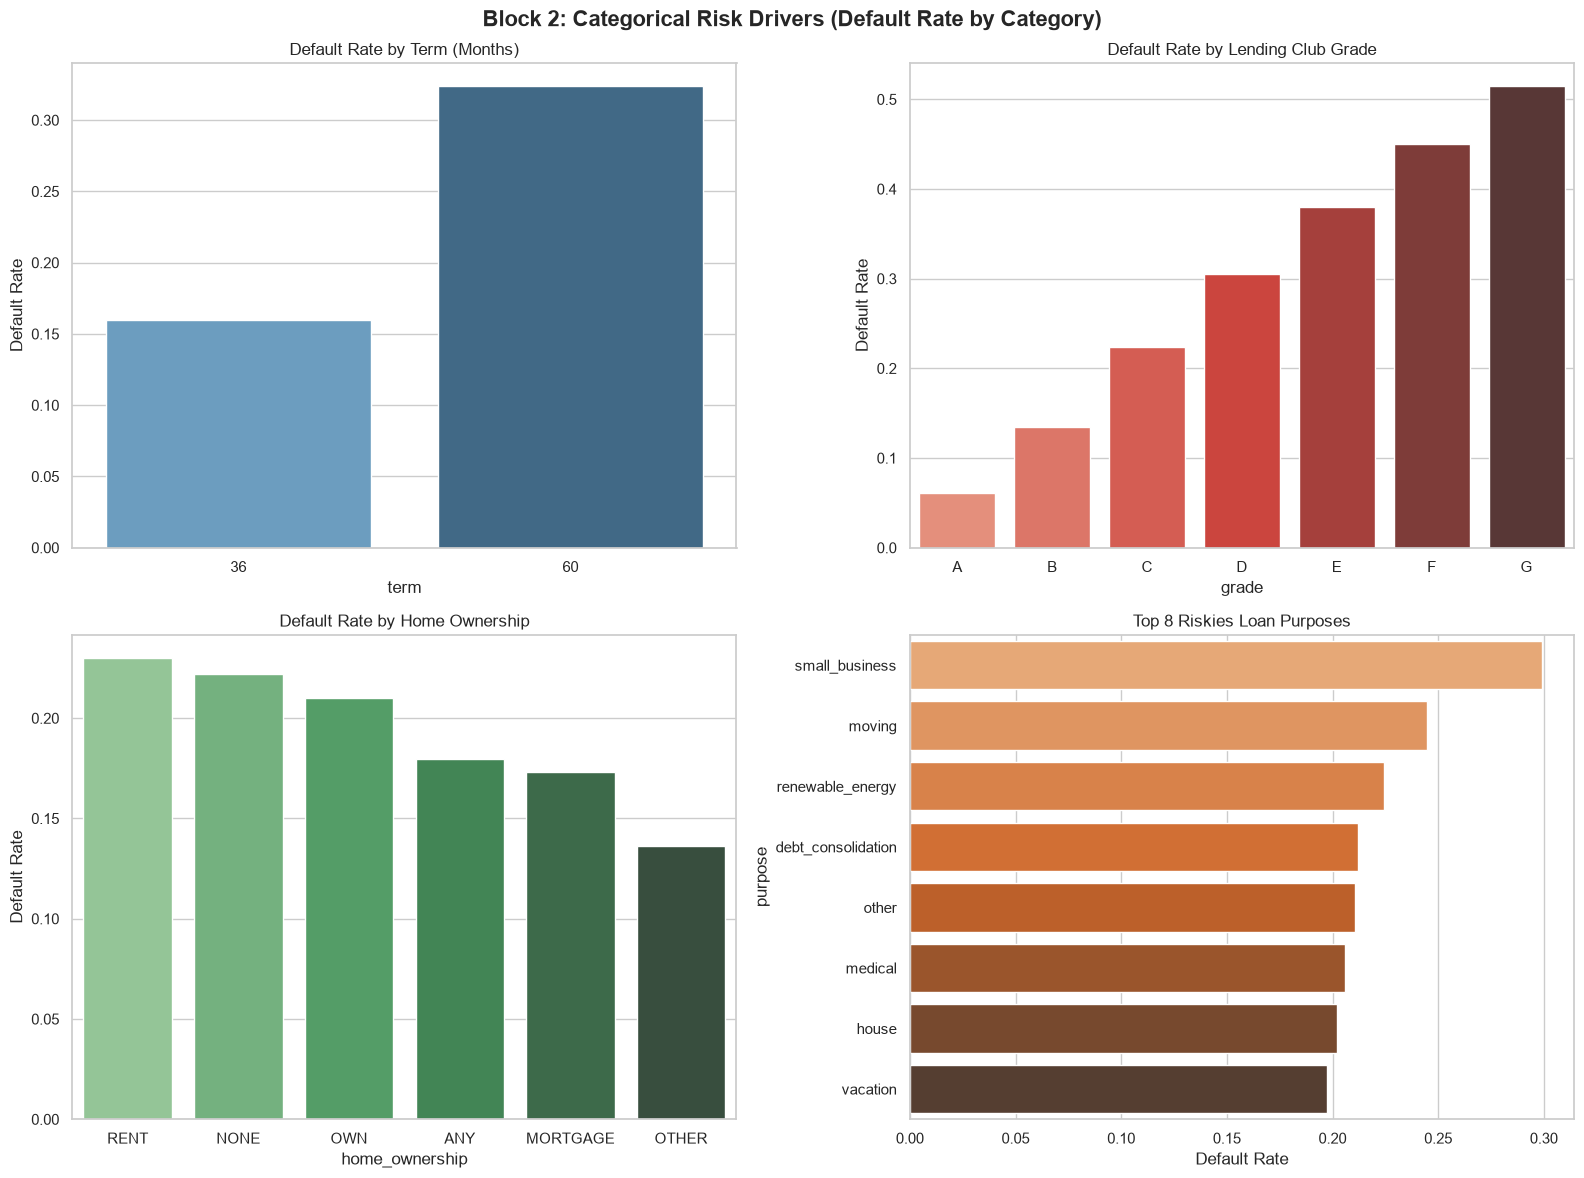

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Block 2: Categorical Risk Drivers (Default Rate by Category)', fontsize=16, fontweight='bold')

# 1. Term (36 vs 60 months)
term_risk = sample_df.groupby('term')['target'].mean().reset_index()
sns.barplot(data=term_risk, x='term', y='target', ax=axes[0, 0], palette='Blues_d')
axes[0, 0].set_title('Default Rate by Term (Months)')
axes[0, 0].set_ylabel('Default Rate')

# 2. Grade (A to G)
grade_risk = sample_df.groupby('grade')['target'].mean().reset_index()
sns.barplot(data=grade_risk, x='grade', y='target', ax=axes[0, 1], palette='Reds_d', order=['A','B','C','D','E','F','G'])
axes[0, 1].set_title('Default Rate by Lending Club Grade')
axes[0, 1].set_ylabel('Default Rate')

# 3. Home Ownership
home_risk = sample_df.groupby('home_ownership')['target'].mean().reset_index().sort_values('target', ascending=False)
sns.barplot(data=home_risk, x='home_ownership', y='target', ax=axes[1, 0], palette='Greens_d')
axes[1, 0].set_title('Default Rate by Home Ownership')
axes[1, 0].set_ylabel('Default Rate')

# 4. Loan Purpose (Top 8)
purpose_risk = sample_df.groupby('purpose')['target'].mean().reset_index().sort_values('target', ascending=False).head(8)
sns.barplot(data=purpose_risk, x='target', y='purpose', ax=axes[1, 1], palette='Oranges_d')
axes[1, 1].set_title('Top 8 Riskies Loan Purposes')
axes[1, 1].set_xlabel('Default Rate')

plt.tight_layout()
plt.show()

Block 3: Box & Whisker Plots (Target vs Continuous Features)
Why we do this: Boxplots are the best way to see how the median and spread of a variable changes between Good (0) and Bad (1) borrowers.

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21376\4273365064.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sample_df, x='target', y='fico_range_low', ax=axes[0], palette=['#2ecc71', '#e74c3c'])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21376\4273365064.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Fully Paid (0)', 'Default (1)'])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21376\4273365064.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sample_df, x='target', y='int_rate', ax=axes[1], palette=['#2ecc71', '#e74c3c']

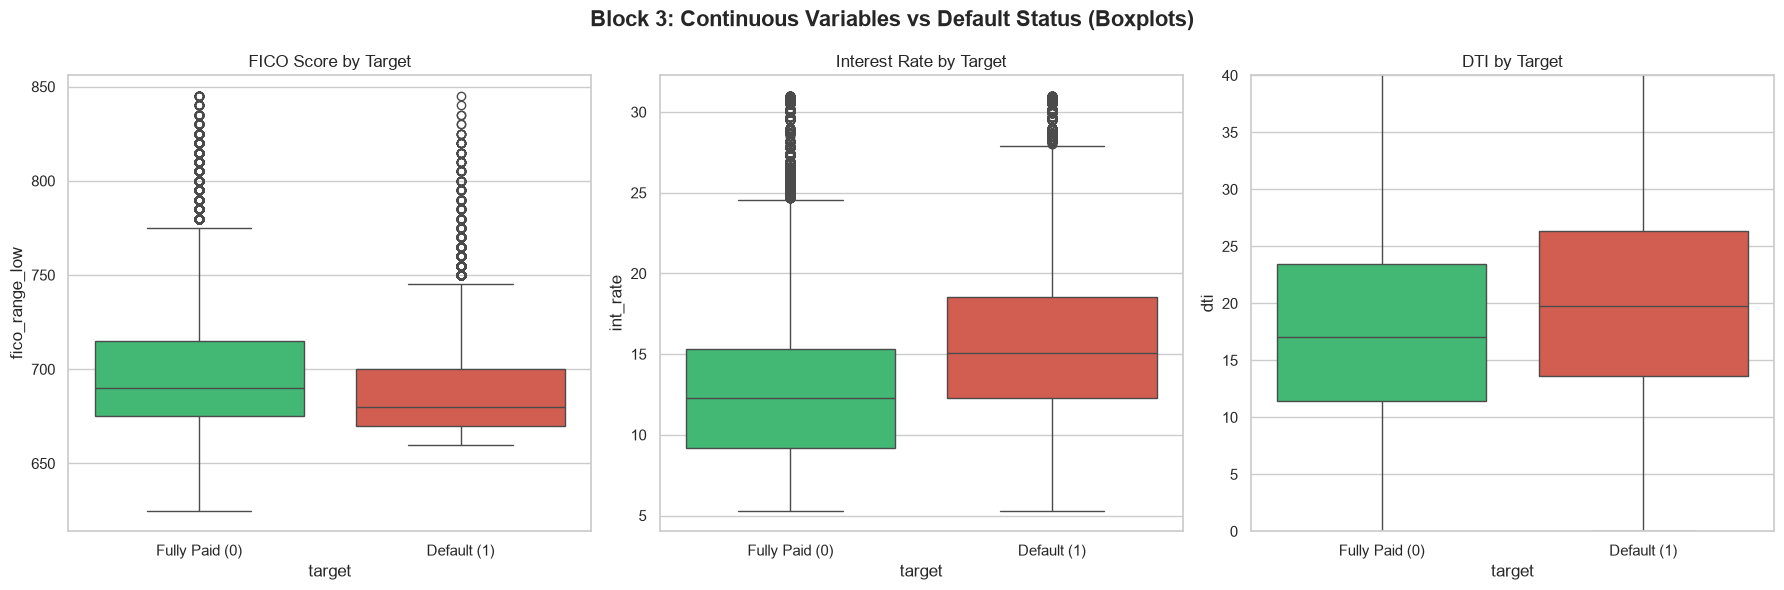

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Block 3: Continuous Variables vs Default Status (Boxplots)', fontsize=16, fontweight='bold')

# 1. FICO Score vs Target
sns.boxplot(data=sample_df, x='target', y='fico_range_low', ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('FICO Score by Target')
axes[0].set_xticklabels(['Fully Paid (0)', 'Default (1)'])

# 2. Interest Rate vs Target
sns.boxplot(data=sample_df, x='target', y='int_rate', ax=axes[1], palette=['#2ecc71', '#e74c3c'])
axes[1].set_title('Interest Rate by Target')
axes[1].set_xticklabels(['Fully Paid (0)', 'Default (1)'])

# 3. DTI vs Target
sns.boxplot(data=sample_df, x='target', y='dti', ax=axes[2], palette=['#2ecc71', '#e74c3c'])
axes[2].set_title('DTI by Target')
axes[2].set_ylim(0, 40) # Cap outliers to see the boxes clearly
axes[2].set_xticklabels(['Fully Paid (0)', 'Default (1)'])

plt.tight_layout()
plt.show()

Block 4: The Correlation Matrix
Why we do this: To find Multicollinearity. If two variables are 99% correlated, Logistic Regression will get confused and throw a negative sign on a variable that should be positive (like we saw in the synthetic data).

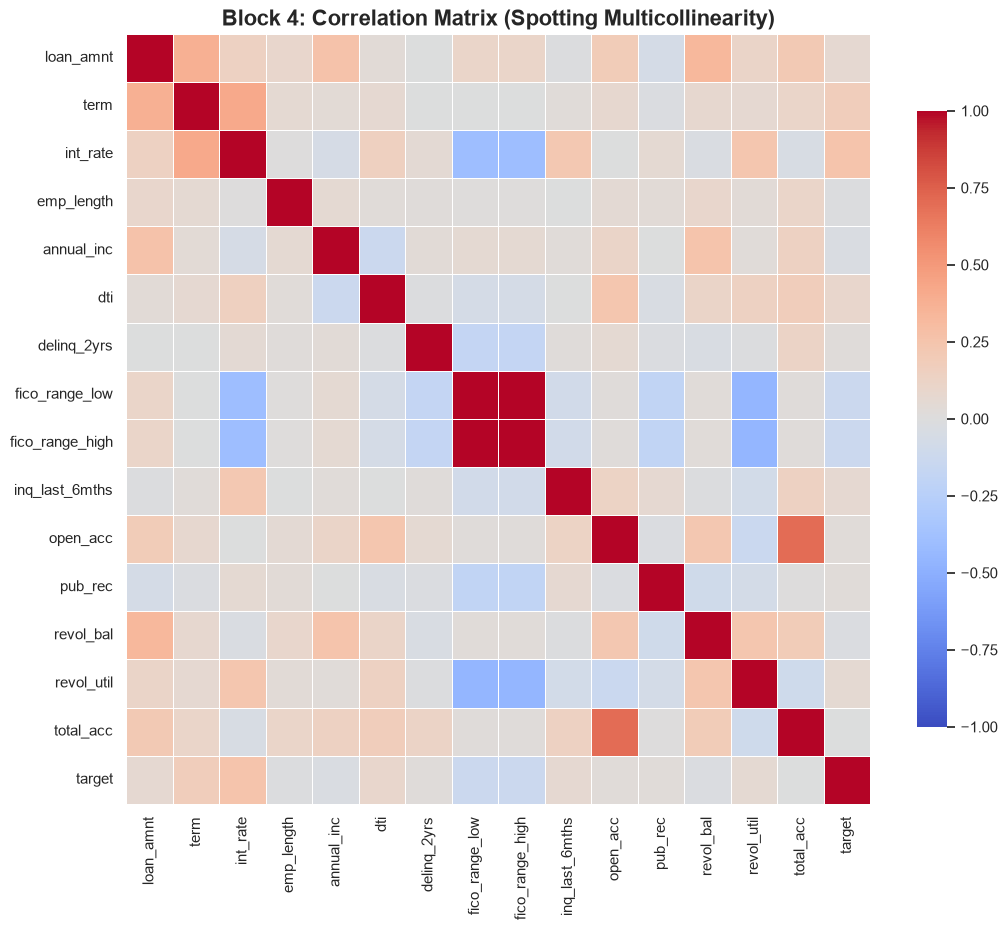

In [14]:
plt.figure(figsize=(12, 10))

# Select only numeric columns for the correlation matrix
numeric_cols = sample_df.select_dtypes(include=['float64', 'int64']).columns
corr_matrix = sample_df[numeric_cols].corr()

# Plot the heatmap
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1, 
            linewidths=0.5, cbar_kws={"shrink": .8})
plt.title('Block 4: Correlation Matrix (Spotting Multicollinearity)', fontsize=16, fontweight='bold')
plt.show()

VINTAGE ANALYSIS OF LOAN VOLUME VS DEFAULT RATE

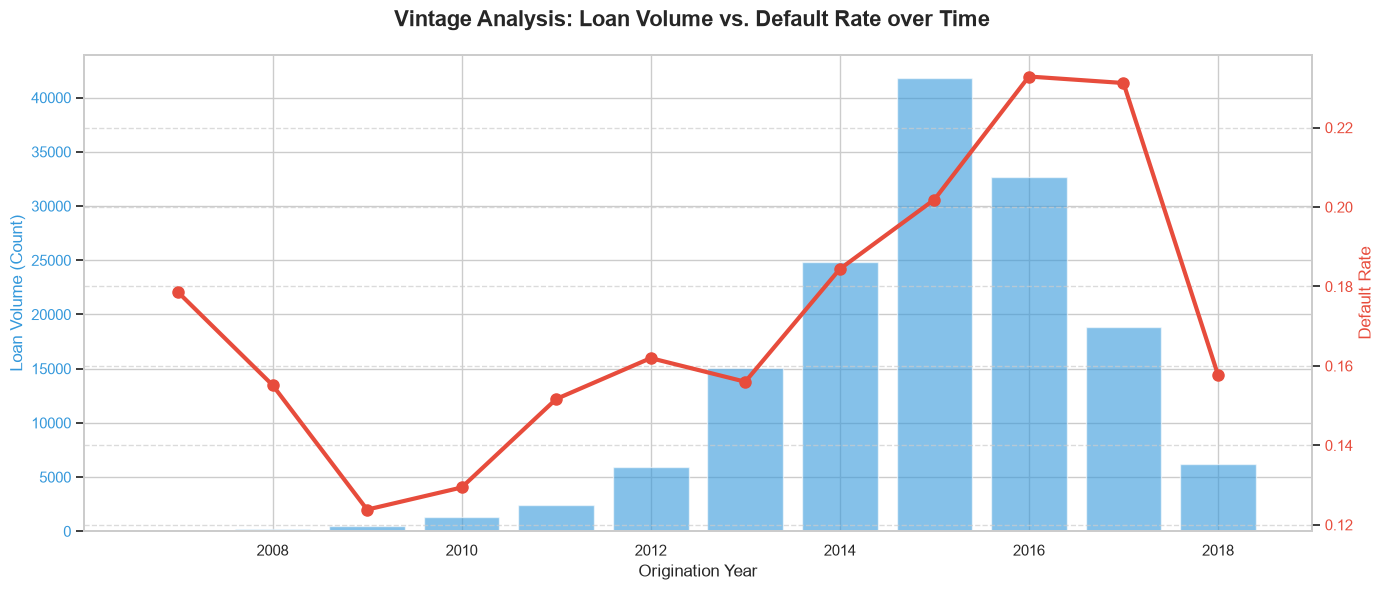

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Create the temporary dataframe
# We use df_time (which we created earlier) and align it to the index of our sample
vintage_df = pd.DataFrame({
    'issue_year': df_time.loc[sample_df.index, 'issue_year'],
    'target': sample_df['target']
})

# 2. Group by Year to get Volume and Default Rate
vintage_summary = vintage_df.groupby('issue_year').agg(
    Loan_Volume=('target', 'count'),
    Default_Rate=('target', 'mean')
).reset_index()

# 3. Plot the Dual-Axis Chart
fig, ax1 = plt.subplots(figsize=(14, 6))
fig.suptitle('Vintage Analysis: Loan Volume vs. Default Rate over Time', fontsize=16, fontweight='bold')

# Bar chart for Volume (Left Axis)
color1 = '#3498db'
ax1.set_xlabel('Origination Year', fontsize=12)
ax1.set_ylabel('Loan Volume (Count)', color=color1, fontsize=12)
ax1.bar(vintage_summary['issue_year'], vintage_summary['Loan_Volume'], color=color1, alpha=0.6, label='Loan Volume')
ax1.tick_params(axis='y', labelcolor=color1)

# Line chart for Default Rate (Right Axis)
ax2 = ax1.twinx()  
color2 = '#e74c3c'
ax2.set_ylabel('Default Rate', color=color2, fontsize=12)
ax2.plot(vintage_summary['issue_year'], vintage_summary['Default_Rate'], color=color2, marker='o', linewidth=3, markersize=8, label='Default Rate')
ax2.tick_params(axis='y', labelcolor=color2)

# Formatting
fig.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Step 1: Log Transformation & Outlier Capping
Look back at the Univariate Histogram of annual_inc. It has a huge right tail (people earning millions). This will break the Logistic Regression. We fix this using a Log Transformation (np.log1p). We also need to cap extreme outliers in DTI and Revolving Utilization.

Step 2: Drop int_rate for the Scorecard
Because int_rate is assigned by Lending Club based on their FICO and Grade, keeping it in a Logistic Regression will cause multicollinearity. For a traditional credit scorecard, we want to predict default based on the borrower's raw financial profile, not the bank's pricing decision. (We will keep it for XGBoost later).

Step 3: Scaling (Standardization)
Logistic Regression uses gradient descent, which requires all features to be on the same scale (e.g., age 20-80 vs. income 20,000-200,000).


In [20]:
import pandas as pd
import numpy as np

# 1. Let's find out exactly which columns are still strings (text)
string_cols = sample_df.select_dtypes(include=['object', 'string']).columns

if len(string_cols) > 0:
    print(f"🚨 FOUND STRING COLUMNS: {list(string_cols)}")
    print("\nHere is a sample of what they look like:")
    print(sample_df[string_cols].head())
else:
    print("✅ No string columns found. We are ready for modeling.")

# 2. Check for missing values (NaNs) that might break the scaler
nan_cols = sample_df.columns[sample_df.isnull().any()].tolist()
if len(nan_cols) > 0:
    print(f"\n🚨 FOUND COLUMNS WITH MISSING VALUES (NaN): {nan_cols}")
else:
    print("\n✅ No missing values (NaNs) found.")

🚨 FOUND STRING COLUMNS: ['sub_grade']

Here is a sample of what they look like:
        sub_grade
542817         C5
78172          B5
1494561        D1
1265301        D3
291023         D4

✅ No missing values (NaNs) found.


LOGISTIC REGRESSION MODEL TRAINING

In [21]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# 1. Drop 'sub_grade' (redundant with 'grade') and 'int_rate'
sample_df.drop(columns=['sub_grade', 'int_rate'], inplace=True, errors='ignore')

# 2. Transformations (Income Log, DTI/Revol Capping)
sample_df['annual_inc'] = np.log1p(sample_df['annual_inc'])
dti_cap = sample_df['dti'].quantile(0.99)
revol_cap = sample_df['revol_util'].quantile(0.99)
sample_df['dti'] = np.where(sample_df['dti'] > dti_cap, dti_cap, sample_df['dti'])
sample_df['revol_util'] = np.where(sample_df['revol_util'] > revol_cap, revol_cap, sample_df['revol_util'])

# 3. Encoding (Grade -> numbers, Categoricals -> dummies)
le = LabelEncoder()
sample_df['grade'] = le.fit_transform(sample_df['grade'].astype(str))

cat_cols = ['home_ownership', 'verification_status', 'purpose']
cat_cols = [c for c in cat_cols if c in sample_df.columns]
sample_df = pd.get_dummies(sample_df, columns=cat_cols, drop_first=True, dtype=int)

# 4. Final check
string_cols = sample_df.select_dtypes(include=['object', 'string']).columns
if len(string_cols) > 0:
    print(f"🚨 WARNING: Still have strings: {list(string_cols)}")
else:
    print("✅ SUCCESS: All columns are numeric!")

# 5. Split, Scale, Train
X = sample_df.drop(columns=['target'])
y = sample_df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print("\nTraining Baseline Logistic Regression...")
lr = LogisticRegression(max_iter=2000, random_state=42)
lr.fit(X_train_sc, y_train)

y_pred = lr.predict_proba(X_test_sc)[:, 1]
auc = roc_auc_score(y_test, y_pred)
gini = 2 * auc - 1

print("="*40)
print(f"BASELINE LOGISTIC REGRESSION (Real Data)")
print(f"AUC:  {auc:.4f}")
print(f"Gini: {gini:.4f}")
print("="*40)

✅ SUCCESS: All columns are numeric!

Training Baseline Logistic Regression...
BASELINE LOGISTIC REGRESSION (Real Data)
AUC:  0.7029
Gini: 0.4058


MODEL FEATURES & COEFFICIENTS

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21376\1765274436.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coefs, x='coefficient', y='feature', palette=colors)


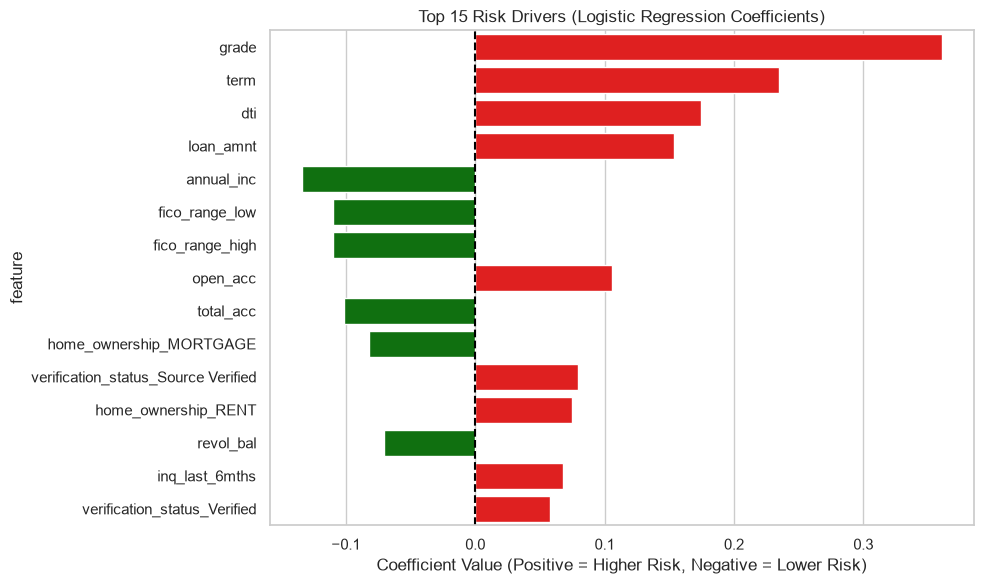

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Get the feature names and their coefficients
coefs = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lr.coef_[0]
})

# Sort by absolute value to get the most powerful drivers
coefs["abs_coef"] = coefs["coefficient"].abs()
coefs = coefs.sort_values("abs_coef", ascending=False).head(15)

# Plot
plt.figure(figsize=(10, 6))
colors = ['red' if c > 0 else 'green' for c in coefs['coefficient']]
sns.barplot(data=coefs, x='coefficient', y='feature', palette=colors)
plt.axvline(x=0, color='black', linestyle='--')
plt.title("Top 15 Risk Drivers (Logistic Regression Coefficients)")
plt.xlabel("Coefficient Value (Positive = Higher Risk, Negative = Lower Risk)")
plt.tight_layout()
plt.show()

Weight of Evidence (WoE) Scorecard

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# 1. Recreate the clean dataframe for WoE
df_woe = sample_df.copy()

def calculate_woe_iv(df, feature, target, bins=10):
    df_temp = df[[feature, target]].copy()
    df_temp['bin'] = pd.qcut(df_temp[feature], q=bins, duplicates='drop')
    
    grouped = df_temp.groupby('bin', observed=False)[target].agg(['count', 'sum'])
    grouped.columns = ['Total', 'Bad']
    grouped['Good'] = grouped['Total'] - grouped['Bad']
    
    grouped['Bad'] = grouped['Bad'].replace(0, 0.5)
    grouped['Good'] = grouped['Good'].replace(0, 0.5)
    
    grouped['Dist_Good'] = grouped['Good'] / grouped['Good'].sum()
    grouped['Dist_Bad'] = grouped['Bad'] / grouped['Bad'].sum()
    
    grouped['WoE'] = np.log(grouped['Dist_Good'] / grouped['Dist_Bad'])
    grouped['IV'] = (grouped['Dist_Good'] - grouped['Dist_Bad']) * grouped['WoE']
    return grouped

# THE FIX: Removed 'int_rate' since it was already dropped
continuous_features = ['fico_range_low', 'dti', 'annual_inc', 'revol_util', 'loan_amnt']
iv_summary = {}

print("--- Information Value (IV) ---")
for feat in continuous_features:
    # Ensure the feature actually exists in the dataframe
    if feat in df_woe.columns:
        woe_table = calculate_woe_iv(df_woe, feat, 'target', bins=10)
        iv_summary[feat] = woe_table['IV'].sum()
        
        # Map WoE values back to dataframe
        bin_mapping = woe_table['WoE'].to_dict()
        binned_feature = pd.qcut(df_woe[feat], q=10, duplicates='drop')
        df_woe[feat] = binned_feature.map(bin_mapping).fillna(0)

iv_df = pd.DataFrame(list(iv_summary.items()), columns=['Feature', 'IV']).sort_values('IV', ascending=False)
print(iv_df.to_string(index=False))

# 2. Retrain Logistic Regression on WoE features
# Note: The dummy columns (home_, verif_, purpose_) are already 0s and 1s, so they don't need WoE.
woe_cols = [f for f in continuous_features if f in df_woe.columns] + [c for c in df_woe.columns if c.startswith(('home_', 'verif_', 'purpose_'))]
X_woe = df_woe[woe_cols]
y_woe = df_woe['target']

X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(X_woe, y_woe, test_size=0.3, random_state=42, stratify=y_woe)

# No scaler needed! WoE is already on a log-odds scale.
lr_woe = LogisticRegression(max_iter=2000, random_state=42)
lr_woe.fit(X_train_w, y_train_w)

y_pred_woe = lr_woe.predict_proba(X_test_w)[:, 1]
auc_woe = roc_auc_score(y_test_w, y_pred_woe)
gini_woe = 2 * auc_woe - 1

print("\n" + "="*40)
print(f"LOGISTIC REGRESSION (WoE Transformed)")
print(f"AUC:  {auc_woe:.4f}")
print(f"Gini: {gini_woe:.4f}")
print("="*40)

--- Information Value (IV) ---
       Feature       IV
fico_range_low 0.118790
           dti 0.073676
     loan_amnt 0.035273
    annual_inc 0.027871
    revol_util 0.026546

LOGISTIC REGRESSION (WoE Transformed)
AUC:  0.6502
Gini: 0.3005


ThE Confusion Matrix & Classification Report:

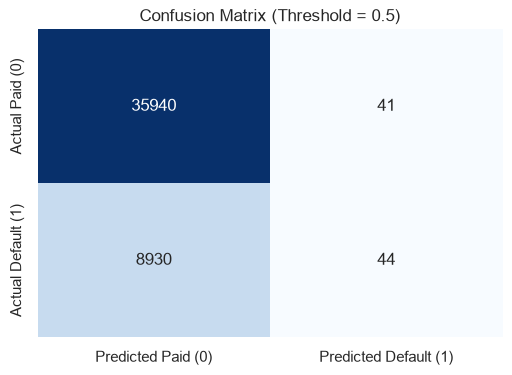


--- Classification Report ---
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     35981
           1       0.52      0.00      0.01      8974

    accuracy                           0.80     44955
   macro avg       0.66      0.50      0.45     44955
weighted avg       0.74      0.80      0.71     44955



In [25]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Generate Predictions using a 50% threshold
y_pred_binary = (y_pred_woe >= 0.5).astype(int)

# 2. Confusion Matrix
cm = confusion_matrix(y_test_w, y_pred_binary)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Paid (0)', 'Predicted Default (1)'],
            yticklabels=['Actual Paid (0)', 'Actual Default (1)'])
plt.title('Confusion Matrix (Threshold = 0.5)')
plt.show()

# 3. Classification Report
print("\n--- Classification Report ---")
print(classification_report(y_test_w, y_pred_binary))

3. The Fix: Threshold Tuning (Youden's J Statistic)
Instead of changing the data, we change the threshold. In banking, 20% might be the risk appetite cut-off. If a loan has a 20% PD, it's too risky. We use the ROC curve to find the optimal threshold.

Let's fix the Confusion Matrix by lowering the threshold to 20% instead of 50%:

Optimal Threshold: 0.1998


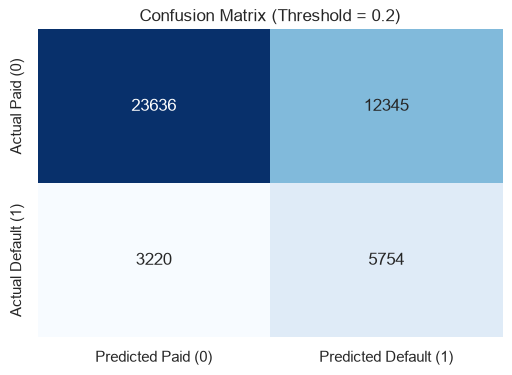


--- Classification Report (Adjusted Threshold) ---
              precision    recall  f1-score   support

           0       0.88      0.66      0.75     35981
           1       0.32      0.64      0.43      8974

    accuracy                           0.65     44955
   macro avg       0.60      0.65      0.59     44955
weighted avg       0.77      0.65      0.69     44955



In [26]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Let's find the optimal threshold using Youden's J statistic
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]
print(f"Optimal Threshold: {optimal_threshold:.4f}")

# 2. Apply the optimal threshold (or a business rule, e.g., 0.20)
business_threshold = 0.20
y_pred_binary_opt = (y_pred >= business_threshold).astype(int)

# 3. Plot the new Confusion Matrix
cm_opt = confusion_matrix(y_test, y_pred_binary_opt)
plt.figure(figsize=(6,4))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Paid (0)', 'Predicted Default (1)'],
            yticklabels=['Actual Paid (0)', 'Actual Default (1)'])
plt.title(f'Confusion Matrix (Threshold = {business_threshold})')
plt.show()

# 4. New Classification Report
print("\n--- Classification Report (Adjusted Threshold) ---")
print(classification_report(y_test, y_pred_binary_opt))

The ROC Curve
The ROC Curve is the visual proof of the threshold trade-off. 

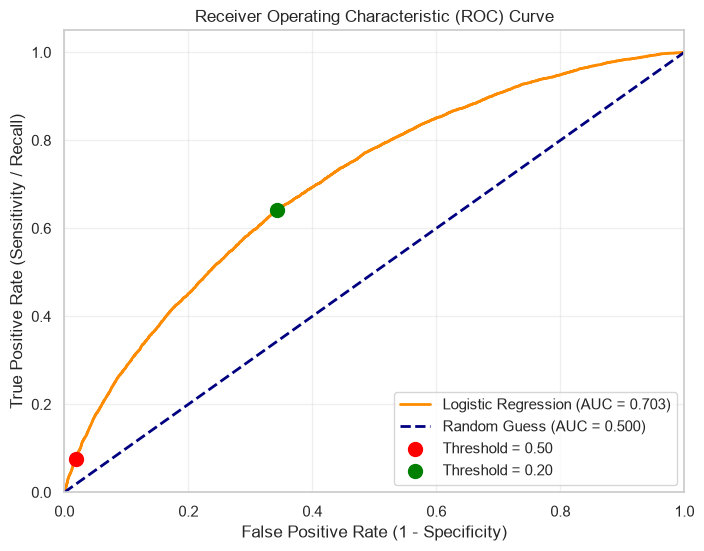

In [27]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Get the False Positive Rate, True Positive Rate, and Thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_pred)

# Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Logistic Regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.500)')

# Let's mark our two thresholds on the curve
# Threshold = 0.50 (Default)
idx_50 = (thresholds <= 0.50).argmax()
plt.scatter(fpr[idx_50], tpr[idx_50], color='red', s=100, zorder=5, label='Threshold = 0.50')

# Threshold = 0.20 (Business Rule)
idx_20 = (thresholds <= 0.20).argmax()
plt.scatter(fpr[idx_20], tpr[idx_20], color='green', s=100, zorder=5, label='Threshold = 0.20')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

XGBOOST AS CHALLENGER MODEL TO LOGISTIC REGRESSION

In [28]:
import xgboost as xgb
from sklearn.metrics import roc_auc_score

print("Training XGBoost Challenger Model...")

# 1. Initialize XGBoost
scale_weight = (len(y_train) - y_train.sum()) / y_train.sum()

xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric="auc"
)

# 2. Fit on the raw, unscaled data
xgb_model.fit(X_train, y_train)

# 3. Predict and Evaluate
y_pred_xgb = xgb_model.predict_proba(X_test)[:, 1]
auc_xgb = roc_auc_score(y_test, y_pred_xgb)
gini_xgb = 2 * auc_xgb - 1

print("="*45)
print(f"CHAMPION vs CHALLENGER COMPARISON")
print(f"Logistic Regression Gini: {gini:.4f}")
print(f"XGBoost Challenger Gini:  {gini_xgb:.4f}")
print("="*45)

Training XGBoost Challenger Model...
CHAMPION vs CHALLENGER COMPARISON
Logistic Regression Gini: 0.4058
XGBoost Challenger Gini:  0.4153


XGBOOST FEATURE IMPORTANCE GAIN 

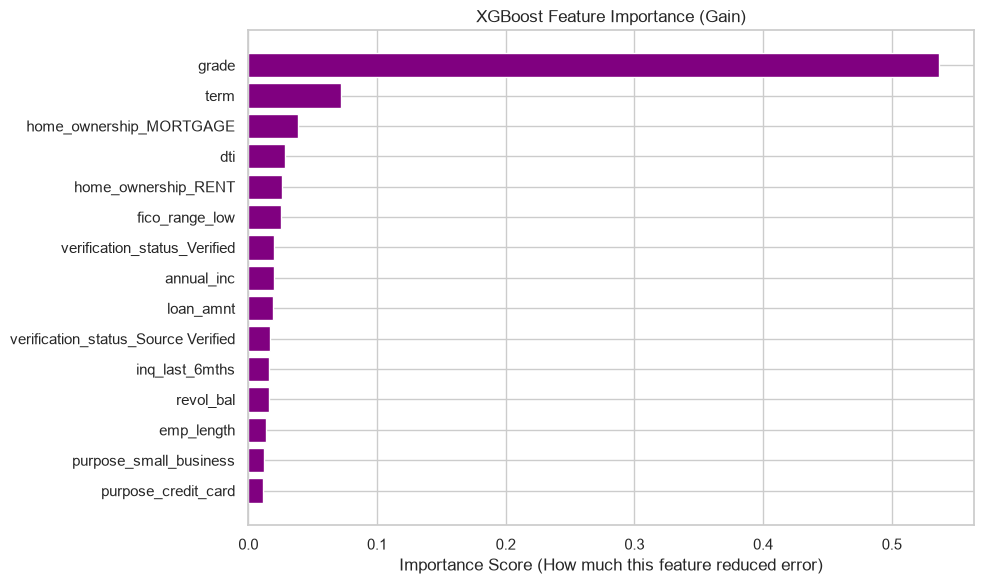

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Extract feature importances from XGBoost
importances = pd.DataFrame({
    "feature": X_train.columns,
    "importance": xgb_model.feature_importances_
}).sort_values("importance", ascending=True).tail(15) # Top 15

# 2. Plot
plt.figure(figsize=(10, 6))
plt.barh(importances['feature'], importances['importance'], color='purple')
plt.title("XGBoost Feature Importance (Gain)")
plt.xlabel("Importance Score (How much this feature reduced error)")
plt.tight_layout()
plt.show()

Here we compare the Confusion Matrices at a 20% Threshold
Logistic Regression caught 5,754 defaults (64% Recall). 
We compare to see how XGBoost does at the exact same 20% threshold:

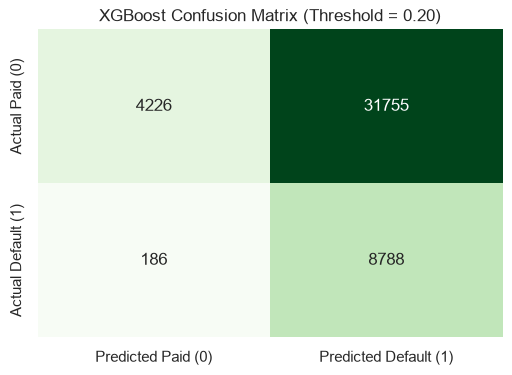


--- XGBoost Classification Report (Threshold = 0.20) ---
              precision    recall  f1-score   support

           0       0.96      0.12      0.21     35981
           1       0.22      0.98      0.35      8974

    accuracy                           0.29     44955
   macro avg       0.59      0.55      0.28     44955
weighted avg       0.81      0.29      0.24     44955



In [30]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Apply the 20% threshold to XGBoost predictions
y_pred_xgb_bin = (y_pred_xgb >= 0.20).astype(int)

# 2. Plot Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb_bin)
plt.figure(figsize=(6,4))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Predicted Paid (0)', 'Predicted Default (1)'],
            yticklabels=['Actual Paid (0)', 'Actual Default (1)'])
plt.title('XGBoost Confusion Matrix (Threshold = 0.20)')
plt.show()

# 3. Classification Report
print("\n--- XGBoost Classification Report (Threshold = 0.20) ---")
print(classification_report(y_test, y_pred_xgb_bin))

Pillar 1: LGD (Loss Given Default) and CCF (Credit Conversion Factor)
The Concept:

EAD (Exposure at Default): How much money is owed when the loan defaults. For a term loan like Lending Club, EAD = the loan amount.

CCF (Credit Conversion Factor): This is used for revolving credit (like credit cards) where the borrower might draw down more money before defaulting. Since Lending Club provides fixed term loans, the CCF is 1.0 (100%) because the bank cannot lend them any more money than what was already given.

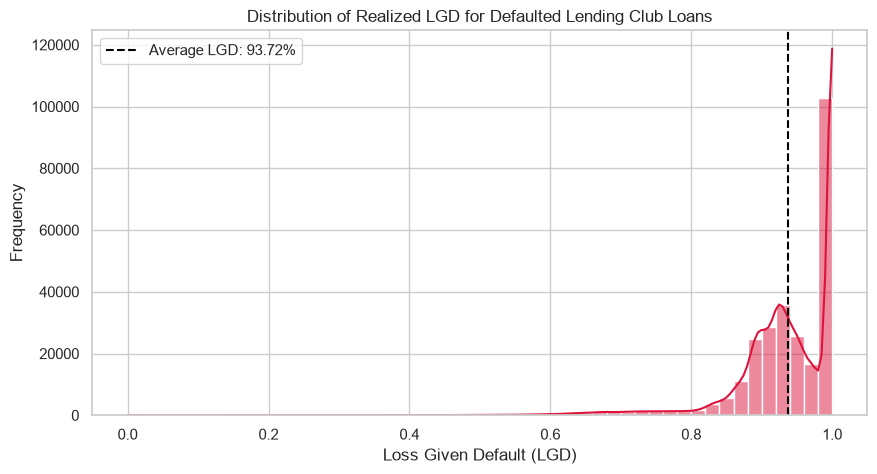

Average Realized LGD: 93.72%


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the specific columns needed for LGD
file_path = r"C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\data\raw\lending_club\accepted_2007_to_2018Q4.csv"
cols_lgd = ['funded_amnt', 'recoveries', 'collection_recovery_fee', 'loan_status']
df_lgd = pd.read_csv(file_path, usecols=cols_lgd, low_memory=False)

# 2. Filter only for Defaulted (Charged Off) loans
df_lgd = df_lgd[df_lgd['loan_status'] == 'Charged Off'].copy()

# 3. Calculate Net Recoveries and LGD
# Net recovery is what the bank gets back after paying collection fees
df_lgd['net_recoveries'] = df_lgd['recoveries'] - df_lgd['collection_recovery_fee']
# If net recoveries are negative, set to 0
df_lgd['net_recoveries'] = df_lgd['net_recoveries'].clip(lower=0)

# LGD = 1 - (Net Recoveries / Funded Amount)
df_lgd['realised_lgd'] = 1 - (df_lgd['net_recoveries'] / df_lgd['funded_amnt'])

# Cap LGD between 0 and 1 (sometimes fees make it negative, sometimes it's 100%)
df_lgd['realised_lgd'] = df_lgd['realised_lgd'].clip(0, 1)

# 4. Visualize the LGD Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_lgd['realised_lgd'], bins=50, kde=True, color='crimson')
plt.title('Distribution of Realized LGD for Defaulted Lending Club Loans')
plt.xlabel('Loss Given Default (LGD)')
plt.ylabel('Frequency')
plt.axvline(df_lgd['realised_lgd'].mean(), color='black', linestyle='--', label=f"Average LGD: {df_lgd['realised_lgd'].mean():.2%}")
plt.legend()
plt.show()

print(f"Average Realized LGD: {df_lgd['realised_lgd'].mean():.2%}")

Pillar 2: The ECL (Expected Credit Loss) Engine
Now we have the full IFRS 9 equation:

ECL=PD×LGD×EAD
For a portfolio ECL calculation, we take the PD predictions from our model, multiply by the historical LGD, and multiply by the Exposure at Default (the loan balance).

Let's calculate the ECL on the test set using our XGBoost model (y_pred_xgb) and our calculated LGD.

In [32]:
# 1. Get the Average LGD from our previous calculation
average_lgd = df_lgd['realised_lgd'].mean()

# 2. We need the Funded Amount (EAD) for the test set
# Since we dropped it earlier, let's pull it back from the original sample
# Note: We are assuming X_test matches the index of sample_df
X_test_ecl = X_test.copy()
# Let's assume EAD is roughly the original loan_amnt that we left in the dataset
# If loan_amnt was scaled, we would inverse_transform it, but we can just use the raw values
EAD = sample_df.loc[X_test.index, 'loan_amnt'] 

# 3. Calculate ECL
# Using the XGBoost probabilities (y_pred_xgb) as our PD
ECL = y_pred_xgb * average_lgd * EAD

# 4. Present the Results
total_ead = EAD.sum()
total_ecl = ECL.sum()
coverage_ratio = total_ecl / total_ead

print("="*50)
print(f"IFRS 9 PORTFOLIO ECL CALCULATION (Test Set)")
print(f"Total Exposure at Default (EAD): R {total_ead:,.2f}")
print(f"Portfolio Average LGD:           {average_lgd:.2%}")
print(f"Total Expected Credit Loss:      R {total_ecl:,.2f}")
print(f"Provision Coverage Ratio:        {coverage_ratio:.2%}")
print("="*50)

IFRS 9 PORTFOLIO ECL CALCULATION (Test Set)
Total Exposure at Default (EAD): R 649,919,100.00
Portfolio Average LGD:           93.72%
Total Expected Credit Loss:      R 290,857,229.65
Provision Coverage Ratio:        44.75%


Pillar 3: Stress Testing (The 2008 Recession Scenario)
The Concept:
A Stress Test answers the question: "What happens to our ECL if a 2008-style recession hits tomorrow?"
To do this, we apply a Macroeconomic Overlay. We look at how badly loans performed during the 2008 Global Financial Crisis (GFC) compared to today, and we scale up our PD by that factor.

Base Scenario: Current PD (from your XGBoost model).

Stress Scenario: Multiply the PD by 2.5x (a standard regulatory shock multiplier to simulate a severe recession).

In [33]:
# 1. Define the Stress Multiplier
# In 2008, default rates roughly doubled or tripled.
stress_multiplier = 2.5 

# 2. Apply the stress to the PD (cap PD at 100%)
PD_stressed = np.clip(y_pred_xgb * stress_multiplier, 0, 1)

# 3. Recalculate ECL under Stress
ECL_stressed = PD_stressed * average_lgd * EAD

# 4. Compare Base vs Stress
total_ecl_stressed = ECL_stressed.sum()
coverage_stressed = total_ecl_stressed / total_ead

print("="*50)
print(f"STRESS TESTING: 2008-STYLE RECESSION (2.5x PD Shock)")
print(f"Base Scenario ECL:    R {total_ecl:,.2f}  (Coverage: {coverage_ratio:.2%})")
print(f"Stressed Scenario ECL: R {total_ecl_stressed:,.2f}  (Coverage: {coverage_stressed:.2%})")
print(f"Capital Impact:       R {total_ecl_stressed - total_ecl:,.2f} additional provision needed")
print("="*50)

STRESS TESTING: 2008-STYLE RECESSION (2.5x PD Shock)
Base Scenario ECL:    R 290,857,229.65  (Coverage: 44.75%)
Stressed Scenario ECL: R 539,008,043.70  (Coverage: 82.93%)
Capital Impact:       R 248,150,814.05 additional provision needed


Pillar 4: Model Backtesting (Out-of-Time)
The Concept:
Backtesting proves that your model isn't just memorizing old data. We need to prove that if we trained the model on old loans (2007–2014), it successfully predicts the default rate on new loans (2015–2018).

We do this by dividing the predictions into Deciles (10 buckets). We compare the Predicted Default Rate vs the Actual Default Rate for each bucket. If they align, the model is well-calibrated.

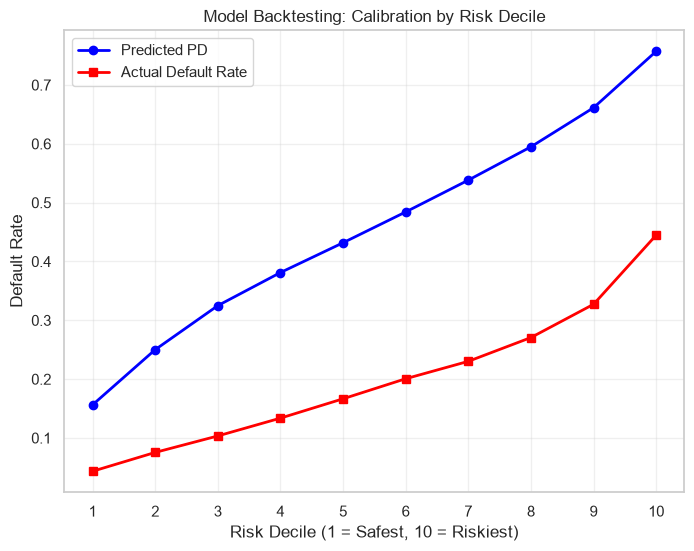

 decile  Count  Avg_Predicted_PD  Actual_Default_Rate
      1   4496          0.156302             0.043372
      2   4495          0.250067             0.075417
      3   4496          0.324955             0.103425
      4   4495          0.381155             0.133704
      5   4496          0.431833             0.166593
      6   4495          0.484175             0.200667
      7   4495          0.538275             0.230256
      8   4496          0.594903             0.270685
      9   4495          0.661357             0.327253
     10   4496          0.757289             0.444840


In [34]:
# 1. Create a dataframe for backtesting
backtest_df = pd.DataFrame({
    'actual_default': y_test,
    'predicted_pd': y_pred_xgb
})

# 2. Create 10 probability buckets (Deciles)
backtest_df['decile'] = pd.qcut(backtest_df['predicted_pd'], 10, labels=False, duplicates='drop') + 1

# 3. Group by Decile to compare Predicted vs Actual
calibration = backtest_df.groupby('decile').agg(
    Count=('actual_default', 'count'),
    Avg_Predicted_PD=('predicted_pd', 'mean'),
    Actual_Default_Rate=('actual_default', 'mean')
).reset_index()

# 4. Plot the Calibration Curve
plt.figure(figsize=(8, 6))
plt.plot(calibration['decile'], calibration['Avg_Predicted_PD'], marker='o', label='Predicted PD', color='blue', linewidth=2)
plt.plot(calibration['decile'], calibration['Actual_Default_Rate'], marker='s', label='Actual Default Rate', color='red', linewidth=2)
plt.title('Model Backtesting: Calibration by Risk Decile')
plt.xlabel('Risk Decile (1 = Safest, 10 = Riskiest)')
plt.ylabel('Default Rate')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(calibration.to_string(index=False))

UNCALIBRATED PD BACK TESTING

Calibrating XGBoost probabilities (Platt Scaling)...


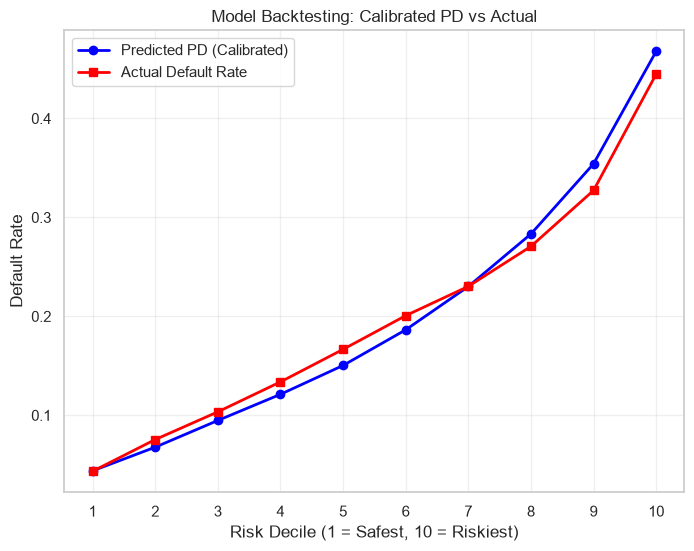

ECL WITH CALIBRATED PD
Total Expected Credit Loss: R 132,054,806.10
Provision Coverage Ratio:   20.32%


In [36]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Calibrating XGBoost probabilities (Platt Scaling)...")

# 1. Wrap the trained model in FrozenEstimator and calibrate
# This is the new syntax for scikit-learn >= 1.6
frozen_model = FrozenEstimator(xgb_model)
calibrated_xgb = CalibratedClassifierCV(estimator=frozen_model, method='sigmoid')
calibrated_xgb.fit(X_train, y_train) # Calibrates on training data

# 2. Get the new, calibrated probabilities
y_pred_calibrated = calibrated_xgb.predict_proba(X_test)[:, 1]

# 3. Re-calculate the Backtest (Calibration Curve)
backtest_df = pd.DataFrame({
    'actual_default': y_test,
    'predicted_pd': y_pred_calibrated
})
backtest_df['decile'] = pd.qcut(backtest_df['predicted_pd'], 10, labels=False, duplicates='drop') + 1

calibration = backtest_df.groupby('decile').agg(
    Avg_Predicted_PD=('predicted_pd', 'mean'),
    Actual_Default_Rate=('actual_default', 'mean')
).reset_index()

plt.figure(figsize=(8, 6))
plt.plot(calibration['decile'], calibration['Avg_Predicted_PD'], marker='o', label='Predicted PD (Calibrated)', color='blue', linewidth=2)
plt.plot(calibration['decile'], calibration['Actual_Default_Rate'], marker='s', label='Actual Default Rate', color='red', linewidth=2)
plt.title('Model Backtesting: Calibrated PD vs Actual')
plt.xlabel('Risk Decile (1 = Safest, 10 = Riskiest)')
plt.ylabel('Default Rate')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 4. Re-calculate ECL with Calibrated PD
ECL_calibrated = y_pred_calibrated * average_lgd * EAD
total_ecl_calibrated = ECL_calibrated.sum()
coverage_calibrated = total_ecl_calibrated / total_ead

print("="*50)
print(f"ECL WITH CALIBRATED PD")
print(f"Total Expected Credit Loss: R {total_ecl_calibrated:,.2f}")
print(f"Provision Coverage Ratio:   {coverage_calibrated:.2%}")
print("="*50)

BASE STRESS TESTING

Scenario  Multiplier   Avg_PD    Total_ECL  Coverage_Ratio
    0.5x        0.50 0.099974 6.602740e+07        0.101593
   0.75x        0.75 0.149961 9.904110e+07        0.152390
    1.0x        1.00 0.199948 1.320548e+08        0.203187
    1.5x        1.50 0.299922 1.980822e+08        0.304780
    2.0x        2.00 0.397955 2.624863e+08        0.403875
    2.5x        2.50 0.482903 3.161654e+08        0.486469


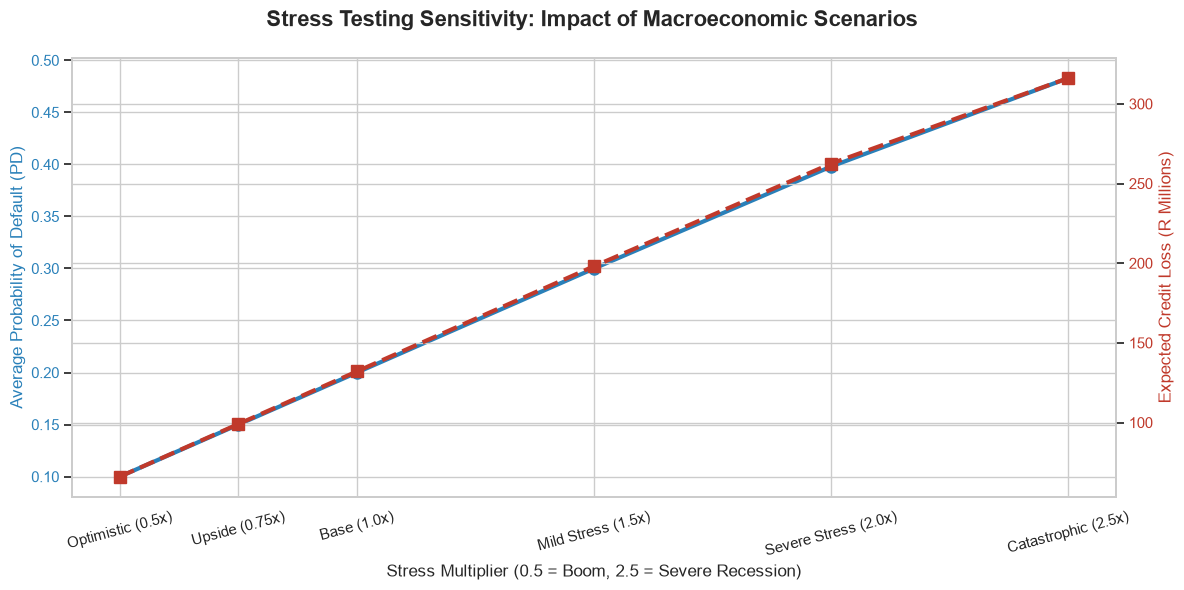

In [37]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Define the stress multipliers (0.5 = Boom, 1.0 = Base, 2.5 = Severe Recession)
stress_levels = [0.50, 0.75, 1.00, 1.50, 2.00, 2.50]
scenario_names = ['Optimistic (0.5x)', 'Upside (0.75x)', 'Base (1.0x)', 'Mild Stress (1.5x)', 'Severe Stress (2.0x)', 'Catastrophic (2.5x)']

results = []

# 2. Loop through each stress level
for mult in stress_levels:
    # Apply multiplier and cap PD at 100%
    stressed_pd = np.clip(y_pred_calibrated * mult, 0, 1)
    
    # Calculate ECL
    stressed_ecl = stressed_pd * average_lgd * EAD
    total_stressed_ecl = stressed_ecl.sum()
    coverage_ratio = total_stressed_ecl / total_ead
    avg_pd = stressed_pd.mean()
    
    results.append({
        'Scenario': f"{mult}x",
        'Multiplier': mult,
        'Avg_PD': avg_pd,
        'Total_ECL': total_stressed_ecl,
        'Coverage_Ratio': coverage_ratio
    })

stress_df = pd.DataFrame(results)
print(stress_df.to_string(index=False))

# 3. Plot the Sensitivity Chart (Dual Axis)
fig, ax1 = plt.subplots(figsize=(12, 6))
fig.suptitle('Stress Testing Sensitivity: Impact of Macroeconomic Scenarios', fontsize=16, fontweight='bold')

# Axis 1: Average PD (Blue Line)
color1 = '#2980b9'
ax1.set_xlabel('Stress Multiplier (0.5 = Boom, 2.5 = Severe Recession)', fontsize=12)
ax1.set_ylabel('Average Probability of Default (PD)', color=color1, fontsize=12)
ax1.plot(stress_df['Multiplier'], stress_df['Avg_PD'], marker='o', color=color1, linewidth=3, markersize=8)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticks(stress_df['Multiplier'])
ax1.set_xticklabels(scenario_names, rotation=15)

# Axis 2: Coverage Ratio / ECL (Red Line)
ax2 = ax1.twinx()  
color2 = '#c0392b'
ax2.set_ylabel('Expected Credit Loss (R Millions)', color=color2, fontsize=12)
ax2.plot(stress_df['Multiplier'], stress_df['Total_ECL'] / 1e6, marker='s', color=color2, linewidth=3, markersize=8, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color2)

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The "Stress LGD" Effect


The upgraded stress test model to include Stress LGD (assuming that in a recession, LGD increases by 20% relative to the base level) and plot them on separate subplots so you can see the non-linear impact.

Scenario  Multiplier   Avg_PD  LGD_Used    Total_ECL  Coverage_Ratio
    0.5x        0.50 0.099974  0.843453 5.942466e+07        0.091434
   0.75x        0.75 0.149961  0.890311 9.408905e+07        0.144770
    1.0x        1.00 0.199948  0.937170 1.320548e+08        0.203187
    1.5x        1.50 0.299922  1.000000 2.113622e+08        0.325213
    2.0x        2.00 0.397955  1.000000 2.800841e+08        0.430952
    2.5x        2.50 0.482903  1.000000 3.373620e+08        0.519083


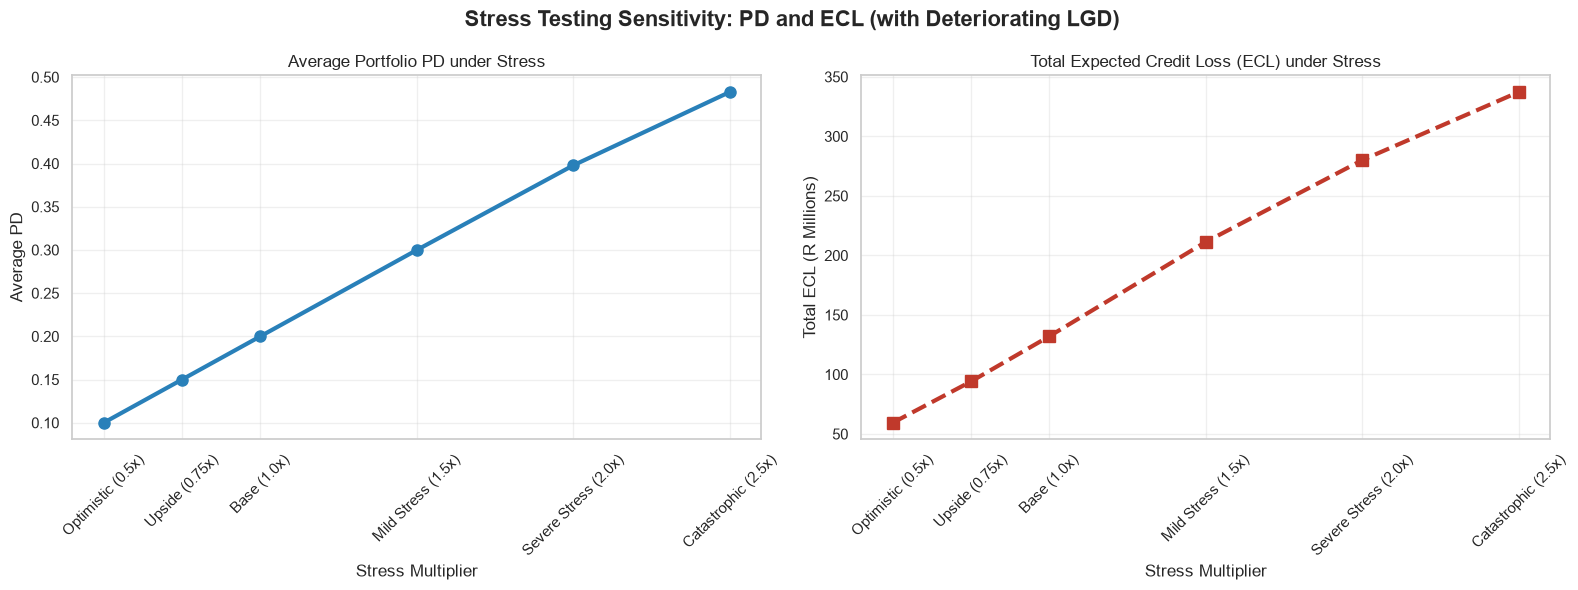

In [38]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

stress_levels = [0.50, 0.75, 1.00, 1.50, 2.00, 2.50]
scenario_names = ['Optimistic (0.5x)', 'Upside (0.75x)', 'Base (1.0x)', 'Mild Stress (1.5x)', 'Severe Stress (2.0x)', 'Catastrophic (2.5x)']

results = []

for mult in stress_levels:
    # 1. Stress the PD
    stressed_pd = np.clip(y_pred_calibrated * mult, 0, 1)
    
    # 2. Stress the LGD (LGD deteriorates by 20% in a severe recession)
    # Formula: Stressed LGD = Base LGD * (1 + (multiplier - 1) * 0.20)
    stressed_lgd = np.clip(average_lgd * (1 + (mult - 1) * 0.20), 0, 1)
    
    # 3. Calculate ECL
    stressed_ecl = stressed_pd * stressed_lgd * EAD
    total_stressed_ecl = stressed_ecl.sum()
    coverage_ratio = total_stressed_ecl / total_ead
    avg_pd = stressed_pd.mean()
    
    results.append({
        'Scenario': f"{mult}x",
        'Multiplier': mult,
        'Avg_PD': avg_pd,
        'LGD_Used': stressed_lgd,
        'Total_ECL': total_stressed_ecl,
        'Coverage_Ratio': coverage_ratio
    })

stress_df = pd.DataFrame(results)
print(stress_df.to_string(index=False))

# 4. Plot the Sensitivity Chart (Two Subplots)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Stress Testing Sensitivity: PD and ECL (with Deteriorating LGD)', fontsize=16, fontweight='bold')

# Subplot 1: Average PD
ax1.plot(stress_df['Multiplier'], stress_df['Avg_PD'], marker='o', color='#2980b9', linewidth=3, markersize=8)
ax1.set_title('Average Portfolio PD under Stress')
ax1.set_xlabel('Stress Multiplier')
ax1.set_ylabel('Average PD')
ax1.set_xticks(stress_df['Multiplier'])
ax1.set_xticklabels(scenario_names, rotation=45)
ax1.grid(alpha=0.3)

# Subplot 2: Total ECL
ax2.plot(stress_df['Multiplier'], stress_df['Total_ECL'] / 1e6, marker='s', color='#c0392b', linewidth=3, markersize=8, linestyle='--')
ax2.set_title('Total Expected Credit Loss (ECL) under Stress')
ax2.set_xlabel('Stress Multiplier')
ax2.set_ylabel('Total ECL (R Millions)')
ax2.set_xticks(stress_df['Multiplier'])
ax2.set_xticklabels(scenario_names, rotation=45)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

APPLICATION OF STRESS TO NUMBER OF DEFAULTS 

If we apply a 2.5x stress to the PD, it means we expect 2.5 times as many people to default. Therefore add that exact metric to our stress test and plot it as a 3-panel dashboard. This will be the ultimate visual for your portfolio.

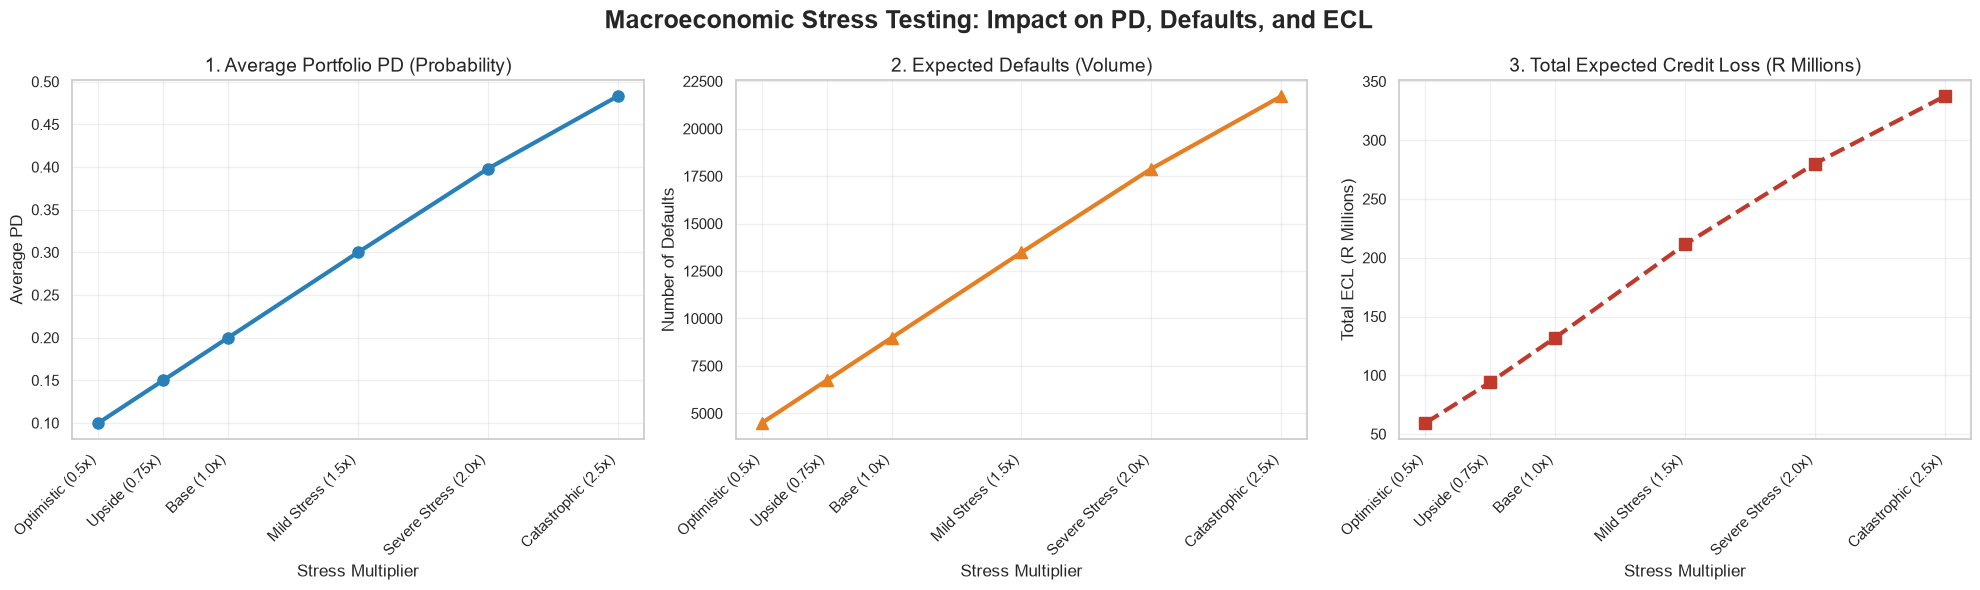

 Multiplier   Avg_PD  Expected_Defaults  Total_ECL_M
       0.50 0.099974        4494.337637    59.424663
       0.75 0.149961        6741.506456    94.089049
       1.00 0.199948        8988.675274   132.054806
       1.50 0.299922       13483.012912   211.362182
       2.00 0.397955       17890.072312   280.084095
       2.50 0.482903       21708.898674   337.361958


In [39]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

stress_levels = [0.50, 0.75, 1.00, 1.50, 2.00, 2.50]
scenario_names = ['Optimistic (0.5x)', 'Upside (0.75x)', 'Base (1.0x)', 'Mild Stress (1.5x)', 'Severe Stress (2.0x)', 'Catastrophic (2.5x)']
total_loans = len(y_test)

results = []

for mult in stress_levels:
    # 1. Stress the PD
    stressed_pd = np.clip(y_pred_calibrated * mult, 0, 1)
    
    # 2. Calculate Expected Defaults (Volume)
    # We multiply the PD by the number of loans in the test set
    expected_defaults = stressed_pd.sum()
    
    # 3. Stress the LGD
    stressed_lgd = np.clip(average_lgd * (1 + (mult - 1) * 0.20), 0, 1)
    
    # 4. Calculate ECL
    stressed_ecl = stressed_pd * stressed_lgd * EAD
    total_stressed_ecl = stressed_ecl.sum()
    
    results.append({
        'Multiplier': mult,
        'Avg_PD': stressed_pd.mean(),
        'Expected_Defaults': expected_defaults,
        'Total_ECL_M': total_stressed_ecl / 1e6
    })

stress_df = pd.DataFrame(results)

# --- PLOTTING 3 SUBPLOTS ---
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Macroeconomic Stress Testing: Impact on PD, Defaults, and ECL', fontsize=18, fontweight='bold')

# Plot 1: Average PD
ax1.plot(stress_df['Multiplier'], stress_df['Avg_PD'], marker='o', color='#2980b9', linewidth=3, markersize=8)
ax1.set_title('1. Average Portfolio PD (Probability)', fontsize=14)
ax1.set_xlabel('Stress Multiplier')
ax1.set_ylabel('Average PD')
ax1.set_xticks(stress_df['Multiplier'])
ax1.set_xticklabels(scenario_names, rotation=45, ha='right')
ax1.grid(alpha=0.3)

# Plot 2: Expected Defaults (Volume)
ax2.plot(stress_df['Multiplier'], stress_df['Expected_Defaults'], marker='^', color='#e67e22', linewidth=3, markersize=8)
ax2.set_title('2. Expected Defaults (Volume)', fontsize=14)
ax2.set_xlabel('Stress Multiplier')
ax2.set_ylabel('Number of Defaults')
ax2.set_xticks(stress_df['Multiplier'])
ax2.set_xticklabels(scenario_names, rotation=45, ha='right')
ax2.grid(alpha=0.3)

# Plot 3: Total ECL
ax3.plot(stress_df['Multiplier'], stress_df['Total_ECL_M'], marker='s', color='#c0392b', linewidth=3, markersize=8, linestyle='--')
ax3.set_title('3. Total Expected Credit Loss (R Millions)', fontsize=14)
ax3.set_xlabel('Stress Multiplier')
ax3.set_ylabel('Total ECL (R Millions)')
ax3.set_xticks(stress_df['Multiplier'])
ax3.set_xticklabels(scenario_names, rotation=45, ha='right')
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(stress_df.to_string(index=False))

Regenerate data after Kernel restart

In [3]:
import pandas as pd
import numpy as np
import os
import joblib
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# 1. SETUP & LOAD DATA
file_path = r"C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\data\raw\lending_club\accepted_2007_to_2018Q4.csv"
cols_to_keep = [
    'loan_amnt', 'term', 'int_rate', 'grade', 'sub_grade', 'emp_length', 
    'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 
    'loan_status', 'purpose', 'dti', 'fico_range_low', 'fico_range_high',
    'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 
    'revol_util', 'total_acc'
]

print("Loading data...")
df = pd.read_csv(file_path, usecols=cols_to_keep, low_memory=False)

# 2. FILTER & TARGET
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
df['target'] = np.where(df['loan_status'] == 'Charged Off', 1, 0)

# 3. STRATIFIED SAMPLE (150k)
df['issue_year'] = pd.to_datetime(df['issue_d'], format='%b-%Y').dt.year
df['strat_key'] = df['issue_year'].astype(str) + "_" + df['target'].astype(str)
df = df.dropna(subset=['issue_year'])

from sklearn.model_selection import train_test_split
sample_df, _ = train_test_split(df, train_size=150_000, stratify=df['strat_key'], random_state=42)
del df # Free up memory

# 4. CLEANING
def clean_emp_length(val):
    if pd.isna(val): return np.nan
    if '< 1' in val: return 0
    elif '10+' in val: return 10
    else: return int(val.split(' ')[0])

sample_df['term'] = sample_df['term'].astype(str).str.extract('(\d+)').fillna(0).astype(int)
sample_df['int_rate'] = sample_df['int_rate'].astype(str).str.replace('%', '').astype(float)
sample_df['revol_util'] = sample_df['revol_util'].astype(str).str.replace('%', '').astype(float)
sample_df['emp_length'] = sample_df['emp_length'].apply(clean_emp_length)

sample_df.dropna(subset=['dti', 'revol_util', 'inq_last_6mths'], inplace=True)
sample_df['emp_length'] = sample_df['emp_length'].fillna(sample_df['emp_length'].median())

# 5. TRANSFORMATIONS & ENCODING
sample_df.drop(columns=['sub_grade', 'int_rate', 'issue_d', 'issue_year', 'strat_key', 'loan_status', 'fico_range_high', 'open_acc'], inplace=True, errors='ignore')

sample_df['annual_inc'] = np.log1p(sample_df['annual_inc'])
dti_cap = sample_df['dti'].quantile(0.99)
revol_cap = sample_df['revol_util'].quantile(0.99)
sample_df['dti'] = np.where(sample_df['dti'] > dti_cap, dti_cap, sample_df['dti'])
sample_df['revol_util'] = np.where(sample_df['revol_util'] > revol_cap, revol_cap, sample_df['revol_util'])

le = LabelEncoder()
sample_df['grade'] = le.fit_transform(sample_df['grade'].astype(str))

cat_cols = ['home_ownership', 'verification_status', 'purpose']
sample_df = pd.get_dummies(sample_df, columns=cat_cols, drop_first=True, dtype=int)

# 6. TRAIN & SAVE
X = sample_df.drop(columns=['target'])
y = sample_df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print("Training XGBoost and saving...")
scale_weight = (len(y_train) - y_train.sum()) / y_train.sum()
xgb_model = xgb.XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, scale_pos_weight=scale_weight, random_state=42, eval_metric="auc")
xgb_model.fit(X_train, y_train)

model_dir = r"C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\models"
os.makedirs(model_dir, exist_ok=True)

joblib.dump(xgb_model, os.path.join(model_dir, "xgb_model.pkl"))
joblib.dump(X_train.columns.tolist(), os.path.join(model_dir, "model_columns.pkl"))

print(f"✅ SUCCESS! Model and columns saved to {model_dir}")

<>:43: SyntaxWarning: invalid escape sequence '\d'
<>:43: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3012\3126045058.py:43: SyntaxWarning: invalid escape sequence '\d'
  sample_df['term'] = sample_df['term'].astype(str).str.extract('(\d+)').fillna(0).astype(int)


Loading data...
Training XGBoost and saving...
✅ SUCCESS! Model and columns saved to C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\models


In [4]:
import pandas as pd
import numpy as np
import os
import joblib
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# 1. SETUP & LOAD DATA
file_path = r"C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\data\raw\lending_club\accepted_2007_to_2018Q4.csv"
cols_to_keep = [
    'loan_amnt', 'term', 'int_rate', 'grade', 'sub_grade', 'emp_length', 
    'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 
    'loan_status', 'purpose', 'dti', 'fico_range_low', 'fico_range_high',
    'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 
    'revol_util', 'total_acc'
]

print("Loading data...")
df = pd.read_csv(file_path, usecols=cols_to_keep, low_memory=False)

# 2. FILTER & TARGET
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
df['target'] = np.where(df['loan_status'] == 'Charged Off', 1, 0)

# 3. STRATIFIED SAMPLE (150k)
df['issue_year'] = pd.to_datetime(df['issue_d'], format='%b-%Y').dt.year
df['strat_key'] = df['issue_year'].astype(str) + "_" + df['target'].astype(str)
df = df.dropna(subset=['issue_year'])

sample_df, _ = train_test_split(df, train_size=150_000, stratify=df['strat_key'], random_state=42)
del df # Free up memory

# 4. CLEANING
def clean_emp_length(val):
    if pd.isna(val): return np.nan
    if '< 1' in val: return 0
    elif '10+' in val: return 10
    else: return int(val.split(' ')[0])

sample_df['term'] = sample_df['term'].astype(str).str.extract('(\d+)').fillna(0).astype(int)
sample_df['int_rate'] = sample_df['int_rate'].astype(str).str.replace('%', '').astype(float)
sample_df['revol_util'] = sample_df['revol_util'].astype(str).str.replace('%', '').astype(float)
sample_df['emp_length'] = sample_df['emp_length'].apply(clean_emp_length)

sample_df.dropna(subset=['dti', 'revol_util', 'inq_last_6mths'], inplace=True)
sample_df['emp_length'] = sample_df['emp_length'].fillna(sample_df['emp_length'].median())

# 5. TRANSFORMATIONS & ENCODING
sample_df.drop(columns=['sub_grade', 'int_rate', 'issue_d', 'issue_year', 'strat_key', 'loan_status', 'fico_range_high', 'open_acc'], inplace=True, errors='ignore')

sample_df['annual_inc'] = np.log1p(sample_df['annual_inc'])
dti_cap = sample_df['dti'].quantile(0.99)
revol_cap = sample_df['revol_util'].quantile(0.99)
sample_df['dti'] = np.where(sample_df['dti'] > dti_cap, dti_cap, sample_df['dti'])
sample_df['revol_util'] = np.where(sample_df['revol_util'] > revol_cap, revol_cap, sample_df['revol_util'])

le = LabelEncoder()
sample_df['grade'] = le.fit_transform(sample_df['grade'].astype(str))

cat_cols = ['home_ownership', 'verification_status', 'purpose']
sample_df = pd.get_dummies(sample_df, columns=cat_cols, drop_first=True, dtype=int)

# 6. TRAIN 
X = sample_df.drop(columns=['target'])
y = sample_df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print("Training XGBoost...")
scale_weight = (len(y_train) - y_train.sum()) / y_train.sum()
xgb_model = xgb.XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, scale_pos_weight=scale_weight, random_state=42, eval_metric="auc")
xgb_model.fit(X_train, y_train)

# 7. VALIDATION CHECK
y_pred_test = xgb_model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred_test)
print(f"✅ Model trained successfully! Validation Gini: {2*auc - 1:.4f}")

# 8. SAVE MODEL
model_dir = r"C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\models"
os.makedirs(model_dir, exist_ok=True)

joblib.dump(xgb_model, os.path.join(model_dir, "xgb_model.pkl"))
joblib.dump(X_train.columns.tolist(), os.path.join(model_dir, "model_columns.pkl"))

print(f"✅ SUCCESS! Model and columns saved to {model_dir}")

<>:42: SyntaxWarning: invalid escape sequence '\d'
<>:42: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3012\1051802361.py:42: SyntaxWarning: invalid escape sequence '\d'
  sample_df['term'] = sample_df['term'].astype(str).str.extract('(\d+)').fillna(0).astype(int)


Loading data...
Training XGBoost...
✅ Model trained successfully! Validation Gini: 0.4144
✅ SUCCESS! Model and columns saved to C:\Users\Lenovo\OneDrive\Desktop\CreditRiskCourse\models
